# Кейс №3 Прогнозирование открытия банковского депозита

### Цели проекта
- Оценить до начала телефонной кампании, оформит ли клиент срочный вклад по её итогам.
- Сравнить отклик по группам клиентов, каналам связи, месяцам и истории прошлых контактов.
- Подготовить выводы и гипотезы для дальнейшего построения модели.

### Описание данных
В представленном датасете 41 188 наблюдений, 20 признаков и целевая переменная y.
- Данные о клиентах: age, job, marital, education, default, housing, loan.
- Контакт и текущая кампания: contact, month, day_of_week, campaign, duration.
- История прошлых кампаний: pdays, previous, poutcome.
- Экономические показатели: emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed.
- Целевая переменная: y — оформил клиент вклад (yes) или нет (no).

## Импорты и настройки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_theme(style="whitegrid")

COLOR_MAIN = "#4E79A7"
COLOR_NO = "#A7B0BA"
COLOR_YES = "#4E79A7"

## 1. Загрузка и описание данных

### 1.1. Загрузка датасета и приведение типов данных

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")

integer_columns = ["age", "duration", "campaign", "pdays", "previous"]

float_columns = [
    "emp.var.rate", "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
]

category_columns = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome", "y"
]

for column in integer_columns:
    df[column] = pd.to_numeric(df[column], errors="raise").astype("int64")

for column in float_columns:
    df[column] = pd.to_numeric(df[column], errors="raise").astype("float64")

for column in category_columns:
    df[column] = df[column].astype("category")

df["month"] = pd.Categorical(
    df["month"],
    categories=["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"],
    ordered=True
)

df["day_of_week"] = pd.Categorical(
    df["day_of_week"],
    categories=["mon", "tue", "wed", "thu", "fri"],
    ordered=True
)

df["y"] = pd.Categorical(df["y"], categories=["no", "yes"])

print(df.shape)
display(df.head())

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.2. Описание столбцов датасета

In [3]:
column_descriptions = {
    "age": "Возраст клиента",
    "job": "Профессия клиента",
    "marital": "Семейное положение",
    "education": "Образование",
    "default": "Информация о просрочке по кредиту",
    "housing": "Наличие жилищного кредита",
    "loan": "Наличие личного кредита",
    "contact": "Канал связи с клиентом",
    "month": "Месяц последнего контакта",
    "day_of_week": "День недели последнего контакта",
    "duration": "Длительность последнего разговора в секундах",
    "campaign": "Число звонков клиенту в текущей кампании",
    "pdays": "Число дней после прошлого контакта; 999 — специальный код",
    "previous": "Число контактов с клиентом до текущей кампании",
    "poutcome": "Результат прошлой кампании",
    "emp.var.rate": "Изменение уровня занятости",
    "cons.price.idx": "Индекс потребительских цен",
    "cons.conf.idx": "Индекс уверенности потребителей",
    "euribor3m": "Ставка Euribor на 3 месяца",
    "nr.employed": "Число занятых",
    "y": "Оформил ли клиент срочный вклад: yes или no",
}

columns_info = pd.DataFrame({
    "Столбец": df.columns,
    "Роль": [
        "Целевая переменная" if column == "y" else "Признак"
        for column in df.columns
    ],
    "Тип данных": [df[column].dtype for column in df.columns],
    "Описание": [
        column_descriptions.get(column, "Описание не добавлено")
        for column in df.columns
    ],
    "Пустые значения": [df[column].isna().sum() for column in df.columns],
    "Примеры значений": [
        ", ".join(df[column].dropna().astype(str).unique()[:4])
        for column in df.columns
    ],
})

display(columns_info)

,Столбец,Роль,Тип данных,Описание,Пустые значения,Примеры значений
0,age,Признак,int64,Возраст клиента,0,"56, 57, 37, 40"
1,job,Признак,category,Профессия клиента,0,"housemaid, services, admin., blue-collar"
2,marital,Признак,category,Семейное положение,0,"married, single, divorced, unknown"
3,education,Признак,category,Образование,0,"basic.4y, high.school, basic.6y, basic.9y"
4,default,Признак,category,Информация о просрочке по кредиту,0,"no, unknown, yes"
5,housing,Признак,category,Наличие жилищного кредита,0,"no, yes, unknown"
6,loan,Признак,category,Наличие личного кредита,0,"no, yes, unknown"
7,contact,Признак,category,Канал связи с клиентом,0,"telephone, cellular"
8,month,Признак,category,Месяц последнего контакта,0,"may, jun, jul, aug"
9,day_of_week,Признак,category,День недели последнего контакта,0,"mon, tue, wed, thu"


### 1.3. Технический паспорт данных

In [4]:
print("Размер:", df.shape)
df.info()

Размер: (41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             41188 non-null  int64   
 1   job             41188 non-null  category
 2   marital         41188 non-null  category
 3   education       41188 non-null  category
 4   default         41188 non-null  category
 5   housing         41188 non-null  category
 6   loan            41188 non-null  category
 7   contact         41188 non-null  category
 8   month           41188 non-null  category
 9   day_of_week     41188 non-null  category
 10  duration        41188 non-null  int64   
 11  campaign        41188 non-null  int64   
 12  pdays           41188 non-null  int64   
 13  previous        41188 non-null  int64   
 14  poutcome        41188 non-null  category
 15  emp.var.rate    41188 non-null  float64 
 16  cons.price.idx  41188 non-null  float64 
 17  con

В наборе 41 188 строк и 21 столбец: 20 признаков и целевая переменная y. Среди столбцов — 11 категориальных, 5 целочисленных и 5 вещественных.

### 1.4. Значения `unknown`

In [5]:
unknown_counts = df.eq("unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)

unknown_summary = pd.DataFrame({
    "Количество": unknown_counts,
    "Доля от всех строк, %": (unknown_counts / len(df) * 100).round(1),
})

display(unknown_summary)

,Количество,"Доля от всех строк, %"
default,8597,20.9
education,1731,4.2
housing,990,2.4
loan,990,2.4
job,330,0.8
marital,80,0.2


unknown означает, что значение не указано. В таблице оно записано как отдельная категория, а не как пустая ячейка NaN. В анализе оставим эту категорию отдельно.

### 1.5. Описательная статистика числовых признаков

In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


По таблице видно, что медианный возраст клиентов — 38 лет. У `previous` в 75% записей значение равно 0. Медиана `pdays` равна 999, но это специальный код, а не число дней. У `duration` и `campaign` максимальные значения намного выше медианных, поэтому дальше посмотрим их распределения на графиках.

### 1.6. Описательная статистика категориальных признаков

In [7]:
categorical_columns = [
    "job", "marital", "education", "default", "housing", "loan",
    "contact", "month", "day_of_week", "poutcome", "y"
]

display(df[categorical_columns].describe().T)

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


Чаще всего в данных встречаются клиенты с профессией `admin.`, состоящие в браке. Самый частый результат кампании — `no`. 

### 1.7. Пропуски и дубликаты в данных

In [8]:
print("Всего пропусков:", df.isna().sum().sum())
print("Полных дубликатов:", df.duplicated().sum())

Всего пропусков: 0
Полных дубликатов: 12


In [9]:
dups = df[df.duplicated(keep=False)]

columns_to_show = [
    "age", "job", "education", "contact", "month",
    "duration", "campaign", "pdays", "previous", "poutcome", "y"
]

display(dups[columns_to_show].head(10))

,age,job,education,contact,month,duration,campaign,pdays,previous,poutcome,y
1265,39,blue-collar,basic.6y,telephone,may,124,1,999,0,nonexistent,no
1266,39,blue-collar,basic.6y,telephone,may,124,1,999,0,nonexistent,no
12260,36,retired,unknown,telephone,jul,88,1,999,0,nonexistent,no
12261,36,retired,unknown,telephone,jul,88,1,999,0,nonexistent,no
14155,27,technician,professional.course,cellular,jul,331,2,999,0,nonexistent,no
14234,27,technician,professional.course,cellular,jul,331,2,999,0,nonexistent,no
16819,47,technician,high.school,cellular,jul,43,3,999,0,nonexistent,no
16956,47,technician,high.school,cellular,jul,43,3,999,0,nonexistent,no
18464,32,technician,professional.course,cellular,jul,128,1,999,0,nonexistent,no
18465,32,technician,professional.course,cellular,jul,128,1,999,0,nonexistent,no


Количество явных пропусков по всем признакам равно 0. Общее количество дубликатов — 12. Удалим их, чтобы не учитывать в дальнейшем анализе.

In [10]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(df.shape, "→", df_clean.shape)

(41188, 21) → (41176, 21)


### 1.7.1 Неявные дубликаты

После удаления полных дубликатов проверим, нет ли записей, которые совпадают после нормализации текстовых значений. Такая проверка выявляет различия в пробелах и регистре, но не позволяет определить повторные записи одного клиента.

In [11]:
normalized = df_clean.copy()

text_columns = normalized.select_dtypes(
    include=["object", "string", "category"]
).columns

for column in text_columns:
    normalized[column] = (
        normalized[column]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

implicit_duplicate_mask = normalized.duplicated(keep=False)

possible_implicit_duplicates = (
    df_clean.loc[implicit_duplicate_mask]
    .sort_index()
)

print(
    "Строк, совпавших после нормализации текста:",
    len(possible_implicit_duplicates)
)

display(possible_implicit_duplicates)

Строк, совпавших после нормализации текста: 0


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y


После удаления полных дубликатов и нормализации текстовых значений дополнительных совпадающих записей не обнаружено. Установить, встречается ли один и тот же клиент в нескольких строках, по этим данным нельзя: в датасете нет идентификатора клиента.

# 2. Одномерный анализ

### 2.1. Баланс классов y (результат кампании)

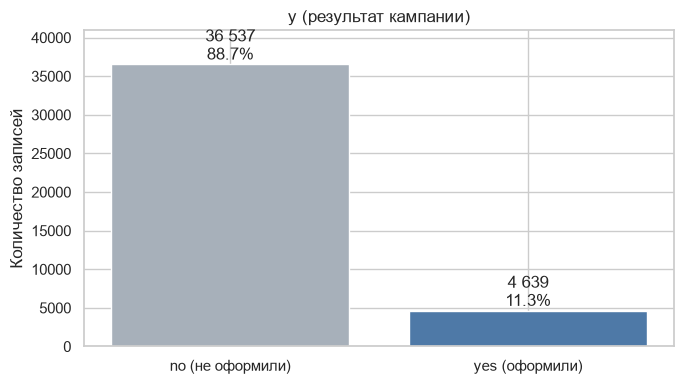

In [12]:
target_counts = df_clean["y"].value_counts().reindex(["no", "yes"])
target_share = (
    df_clean["y"].value_counts(normalize=True).reindex(["no", "yes"]) * 100
)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["no (не оформили)", "yes (оформили)"],
    target_counts.values,
    color=[COLOR_NO, COLOR_YES]
)

for bar, count, share in zip(bars, target_counts.values, target_share.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(count):,}".replace(",", " ") + f"\n{share:.1f}%",
        ha="center",
        va="bottom"
    )

ax.set_title("y (результат кампании)")
ax.set_ylabel("Количество записей")
ax.set_ylim(0, target_counts.max() * 1.12)

plt.tight_layout()
plt.show()

В данных заметен выраженный дисбаланс классов. В 36 537 записях целевая переменная равна no (88,7%), в 4 639 — yes (11,3%). На один ответ yes приходится примерно восемь ответов no. Из-за дисбаланса при оценке будущей модели одной метрики accuracy будет недостаточно. Будем смотреть на precision, recall, F1 и PR-AUC. При разделении данных сохраним долю классов; взвешивание классов или ресемплинг будем применять только на обучающей выборке.

### 2.2. Распределение числовых признаков

Посмотрим, как распределены значения четырёх числовых признаков: возраста клиента, длительности разговора, числа звонков в текущей кампании и числа прошлых контактов. pdays рассмотрим отдельно из-за специального кода 999.

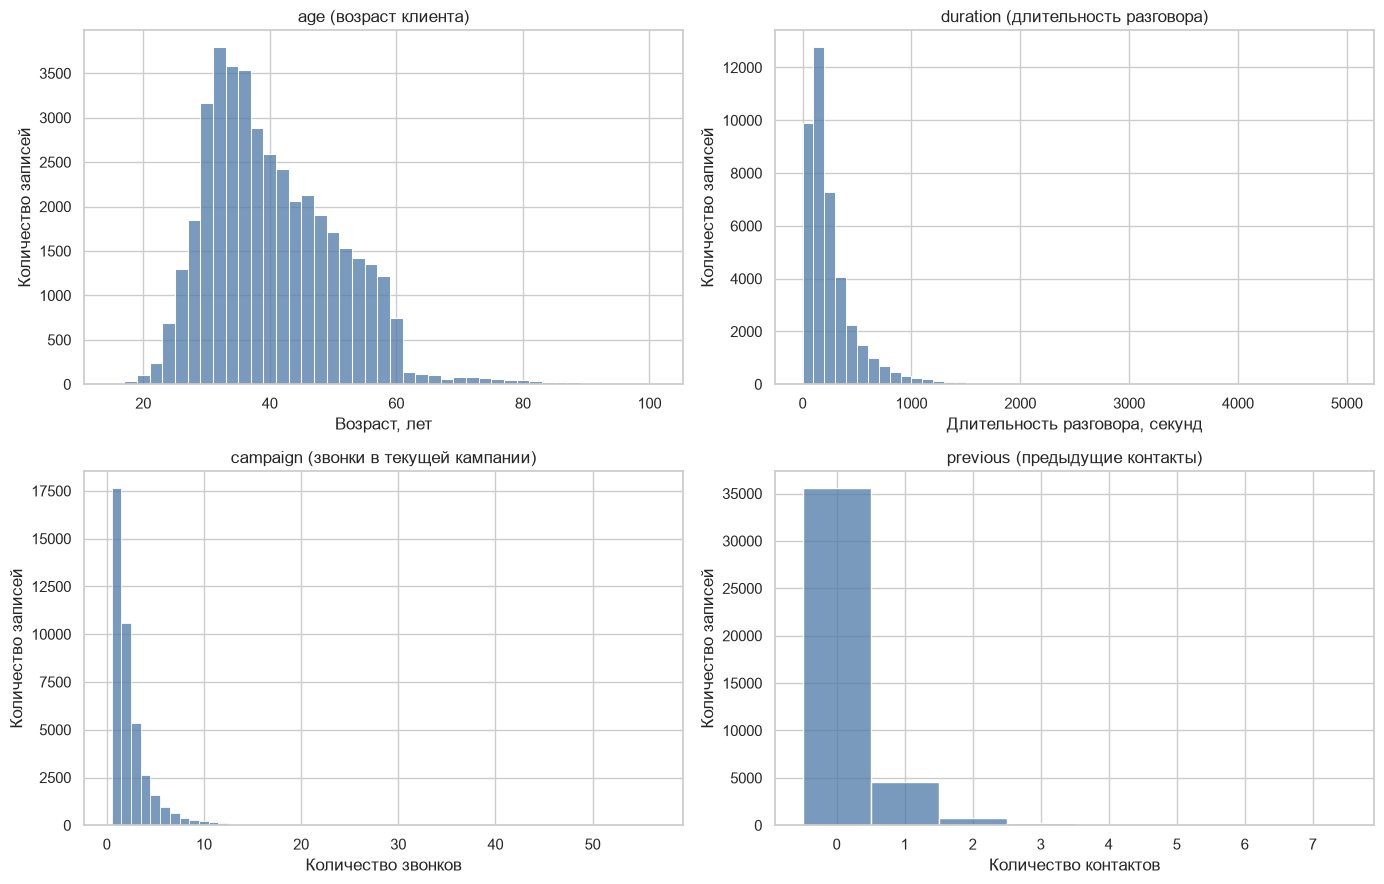

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plots = [
    (
        "age",
        np.arange(15, 102, 2),
        "age (возраст клиента)",
        "Возраст, лет"
    ),
    (
        "duration",
        np.arange(0, 5001, 100),
        "duration (длительность разговора)",
        "Длительность разговора, секунд"
    ),
    (
        "campaign",
        np.arange(0.5, 57.5, 1),
        "campaign (звонки в текущей кампании)",
        "Количество звонков"
    ),
    (
        "previous",
        np.arange(-0.5, 8.5, 1),
        "previous (предыдущие контакты)",
        "Количество контактов"
    )
]

for ax, (column, bins, title, xlabel) in zip(axes.flat, plots):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=bins,
        color=COLOR_MAIN,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Количество записей")

plt.tight_layout()
plt.show()

На гистограммах у duration, campaign и previous есть длинные правые хвосты. Максимальные значения — 4 918 секунд, 56 звонков и 7 прошлых контактов — взяты из таблицы описательной статистики в пункте 1.5. По одному максимальному значению нельзя определить, является ли запись ошибочной, поэтому строки не удаляли.

### 2.3. Анализ выбросов числовых признаков по группам y

Сравним распределения age, duration, campaign и previous у клиентов, которые оформили и не оформили вклад. Точки за пределами «усов» boxplot — потенциальные выбросы; они не обязательно являются ошибками.

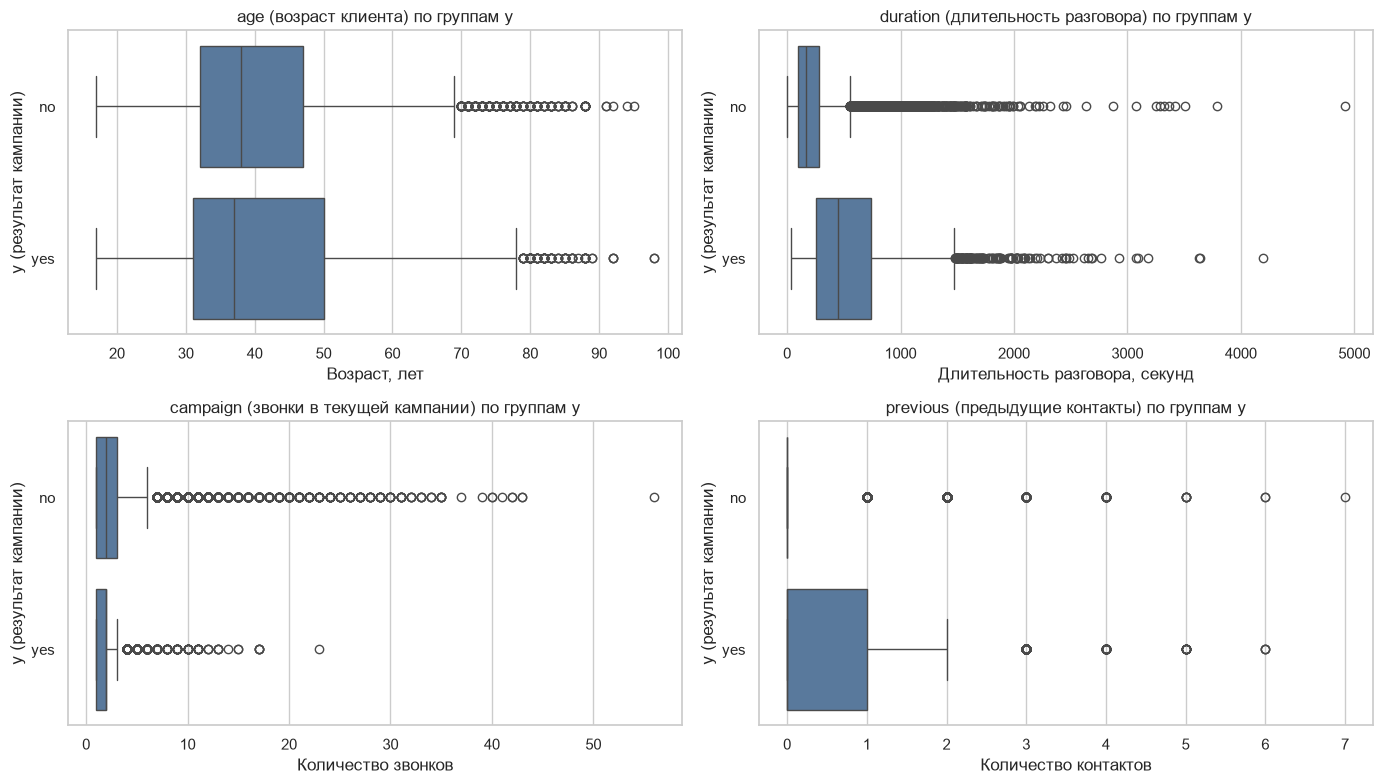

In [14]:
outlier_plots = [
    ("age", "возраст клиента", "Возраст, лет"),
    ("duration", "длительность разговора", "Длительность разговора, секунд"),
    ("campaign", "звонки в текущей кампании", "Количество звонков"),
    ("previous", "предыдущие контакты", "Количество контактов")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (column, name, xlabel) in zip(axes.flat, outlier_plots):
    sns.boxplot(
        data=df_clean,
        x=column,
        y="y",
        order=["no", "yes"],
        color=COLOR_MAIN,
        showfliers=True,
        ax=ax
    )

    ax.set_title(f"{column} ({name}) по группам y")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("y (результат кампании)")

plt.tight_layout()
plt.show()

Распределения age в группах no и yes заметно перекрываются. В группе yes медиана duration выше, а медианное число звонков campaign ниже. Для previous нулевое значение преобладает в обеих группах; ненулевые значения встречаются у клиентов с yes чаще. Точки за пределами «усов» — потенциальные выбросы по правилу boxplot, но это не означает, что данные ошибочны. Особенно осторожно нужно трактовать previous: из-за большого числа нулей boxplot помечает отдельные положительные значения как выбросы. Автоматически удалять их не будем.

Перед обучением модели отдельно проверим, влияют ли крайние значения на качество. Не будем удалять их только по boxplot: это могут быть реальные наблюдения. Любые пороги и преобразования будем определять только на обучающей выборке.

# 3. Многомерный анализ

### 3.1. contact × month: доля откликов y = yes

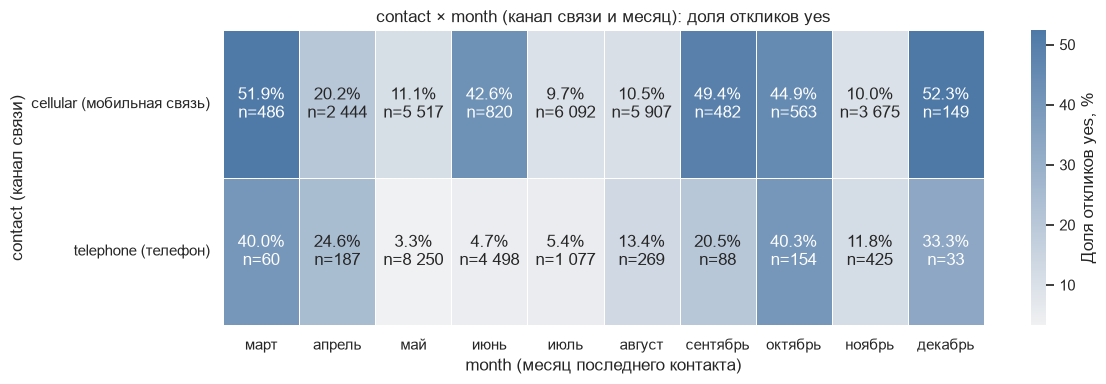

In [15]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_labels = ["март", "апрель", "май", "июнь", "июль",
                "август", "сентябрь", "октябрь", "ноябрь", "декабрь"]
contact_order = ["cellular", "telephone"]

contact_month_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby(["contact", "month"], observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reset_index()
)

rate_matrix = (
    contact_month_summary
    .pivot(index="contact", columns="month", values="response_rate")
    .reindex(index=contact_order, columns=month_order)
)

count_matrix = (
    contact_month_summary
    .pivot(index="contact", columns="month", values="contacts")
    .reindex(index=contact_order, columns=month_order)
)

rate_percent = rate_matrix * 100
annotations = np.empty(rate_matrix.shape, dtype=object)

for i in range(rate_matrix.shape[0]):
    for j in range(rate_matrix.shape[1]):
        rate = rate_matrix.iloc[i, j]
        count = count_matrix.iloc[i, j]

        if pd.isna(rate) or pd.isna(count):
            annotations[i, j] = ""
        else:
            annotations[i, j] = (
                f"{rate * 100:.1f}%\n"
                f"n={int(count):,}".replace(",", " ")
            )

rate_percent.index = [
    "cellular (мобильная связь)",
    "telephone (телефон)"
]
rate_percent.columns = month_labels

fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(
    rate_percent,
    annot=annotations,
    fmt="",
    cmap=sns.light_palette(COLOR_MAIN, as_cmap=True),
    linewidths=0.5,
    cbar_kws={"label": "Доля откликов yes, %"},
    ax=ax
)

ax.set_title("contact × month (канал связи и месяц): доля откликов yes")
ax.set_xlabel("month (месяц последнего контакта)")
ax.set_ylabel("contact (канал связи)")

plt.tight_layout()
plt.show()

В большинстве месяцев доля отклика при мобильной связи выше, чем при телефонной, но это различие наблюдается не всегда и меняется от месяца к месяцу. Например, в мае отклик низкий для обоих каналов: 11,1% при мобильной связи и 3,3% при телефонной. Высокие проценты в отдельных месяцах нужно оценивать вместе с размером группы n. График показывает совместное распределение откликов, но не доказывает, что именно канал или месяц стал причиной различий. Данные за разные годы объединены, поэтому по нему нельзя делать уверенный вывод о сезонности.

### 3.2. Корреляции числовых признаков и y

Для расчёта корреляции закодируем y: no = 0, yes = 1. Матрица покажет, как числовые признаки связаны друг с другом и с результатом кампании. Корреляция не доказывает причинно-следственную связь. pdays не включаем из-за специального значения 999.

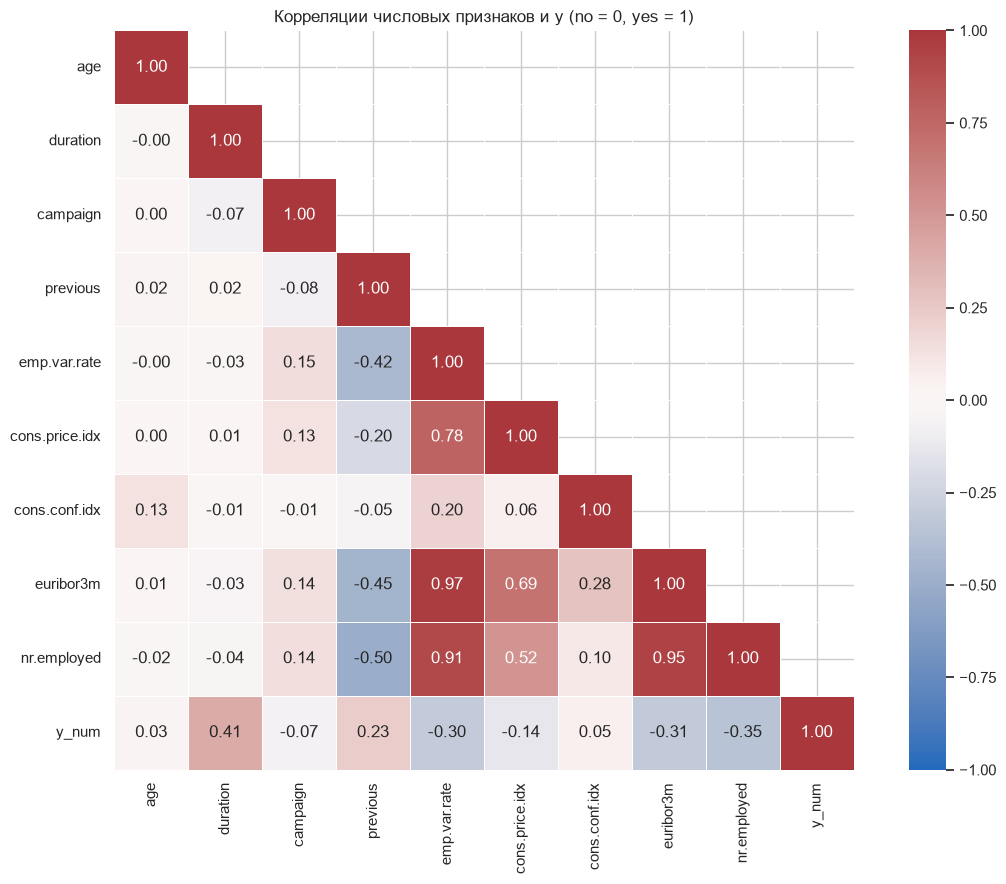

In [16]:
numeric_columns = [
    "age", "duration", "campaign", "previous",
    "emp.var.rate", "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
]

corr_data = df_clean[numeric_columns].copy()
corr_data["y_num"] = (
    df_clean["y"]
    .map({"no": 0, "yes": 1})
    .astype("int8")
)

corr = corr_data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12, 9))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Корреляции числовых признаков и y (no = 0, yes = 1)")

plt.tight_layout()
plt.show()

При построении линейной модели проверим влияние сильно коррелирующих макропризнаков: сравним варианты с разными наборами признаков и с регуляризацией. Решение примем по качеству на проверочной выборке; по одной корреляционной матрице признаки удалять не будем.

# 4. Анализ истории контактов

### 4.1. pdays (давность предыдущего контакта)

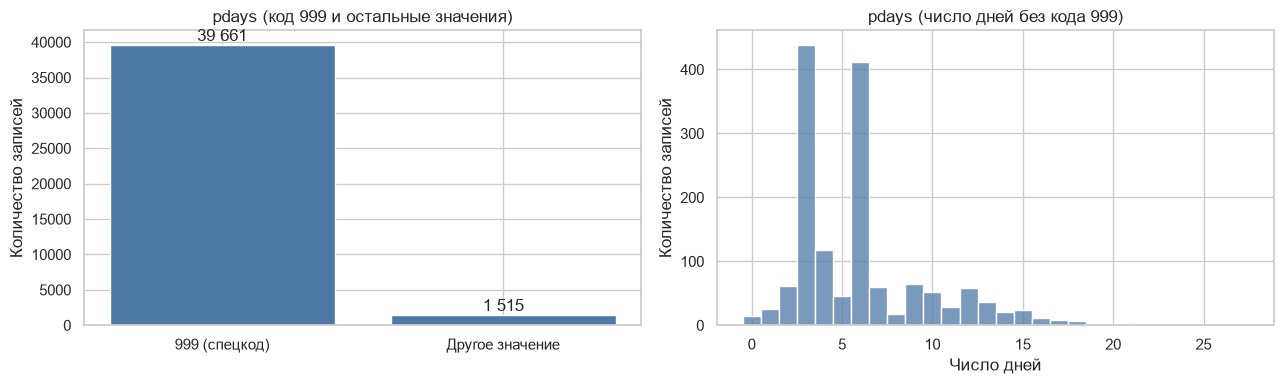

In [17]:
pdays_status = pd.Series(
    np.where(df_clean["pdays"] == 999, "999 (спецкод)", "Другое значение")
).value_counts().reindex(["999 (спецкод)", "Другое значение"])

pdays_real = df_clean.loc[df_clean["pdays"] != 999, "pdays"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

bars = axes[0].bar(
    pdays_status.index,
    pdays_status.values,
    color=COLOR_MAIN
)

for bar, count in zip(bars, pdays_status.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}".replace(",", " "),
        ha="center",
        va="bottom"
    )

axes[0].set_title("pdays (код 999 и остальные значения)")
axes[0].set_ylabel("Количество записей")

sns.histplot(
    x=pdays_real,
    discrete=True,
    color=COLOR_MAIN,
    ax=axes[1]
)

axes[1].set_title("pdays (число дней без кода 999)")
axes[1].set_xlabel("Число дней")
axes[1].set_ylabel("Количество записей")

plt.tight_layout()
plt.show()

Код 999 встречается часто, поэтому на первом графике он показан отдельно. На втором графике видно распределение остальных значений pdays — числа дней после предыдущего контакта.

# 5. Связь признаков с целевой переменной y

### 5.1. job (профессия клиента)

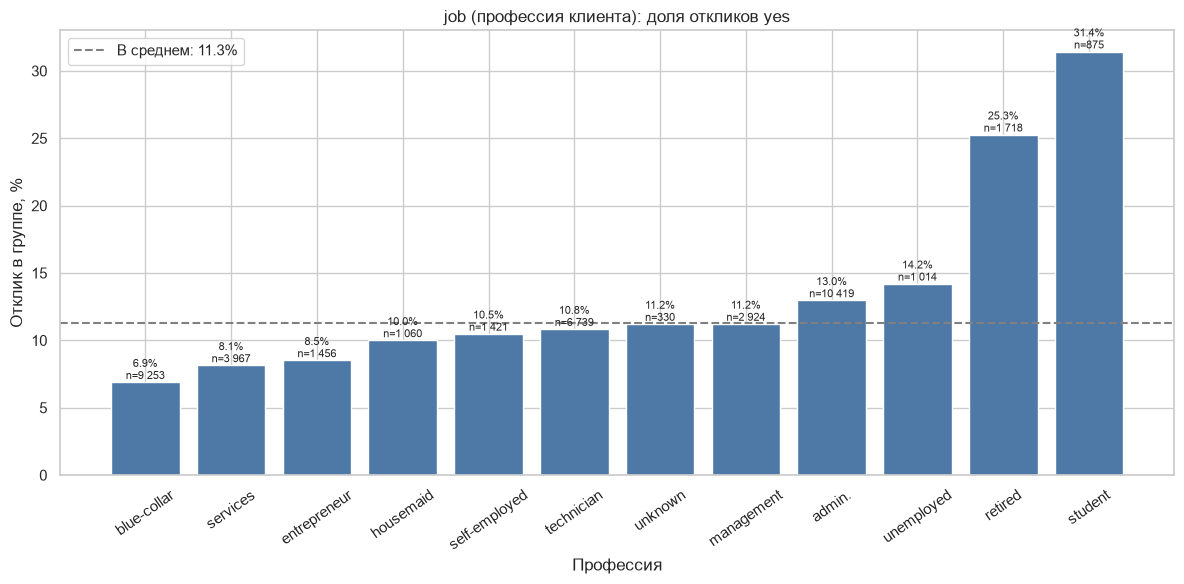

In [18]:
job_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("job", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .sort_values("response_rate")
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    job_summary.index.astype(str),
    job_summary["response_rate"] * 100,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, job_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_title("job (профессия клиента): доля откликов yes")
ax.set_xlabel("Профессия")
ax.set_ylabel("Отклик в группе, %")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()
plt.show()

У студентов доля отклика — 31,4%, у пенсионеров — 25,3%. Это выше среднего по выборке (11,3%). У клиентов рабочих специальностей отклик ниже — 6,9%. В группе unknown (профессия не указана) всего 330 контактов, поэтому её результат стоит оценивать осторожно.

### 5.2. education (образование)

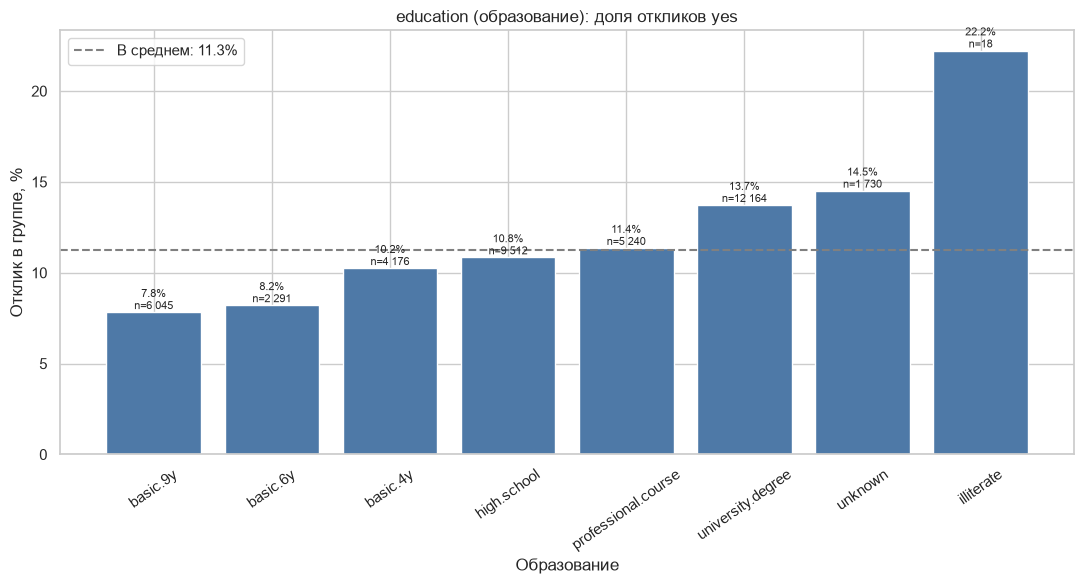

In [19]:
education_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("education", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .sort_values("response_rate")
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    education_summary.index.astype(str),
    education_summary["response_rate"] * 100,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, education_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_title("education (образование): доля откликов yes")
ax.set_xlabel("Образование")
ax.set_ylabel("Отклик в группе, %")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()
plt.show()

Самый высокий отклик в категории illiterate — 22,2%, но там всего 18 контактов, поэтому по ней нельзя делать уверенный вывод. Среди крупных групп доля отклика выше среднего у клиентов с высшим образованием (university.degree) — 13,7%; у клиентов с базовым образованием 6 или 9 лет она ниже среднего — 8,2% и 7,8%. У 1 730 клиентов образование не указано; доля отклика в этой группе — 14,5%.

### 5.3. housing и loan (кредиты)

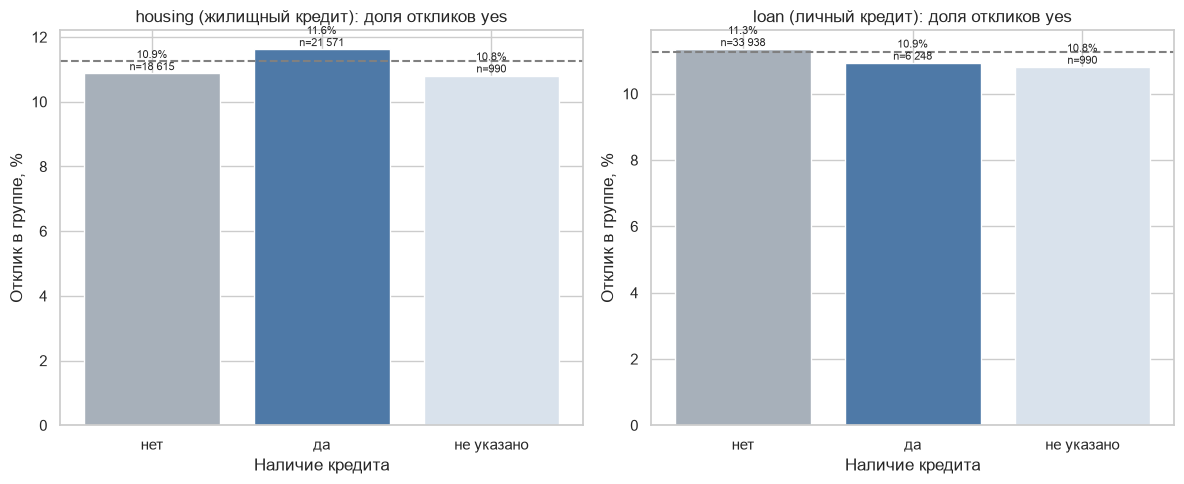

In [20]:
credit_columns = {
    "housing": "housing (жилищный кредит)",
    "loan": "loan (личный кредит)"
}

overall_rate = df_clean["y"].eq("yes").mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (column, title) in zip(axes, credit_columns.items()):
    summary = (
        df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
        .groupby(column, observed=True)
        .agg(
            contacts=("y", "size"),
            response_rate=("is_yes", "mean")
        )
        .reindex(["no", "yes", "unknown"])
    )

    bars = ax.bar(
        ["нет", "да", "не указано"],
        summary["response_rate"] * 100,
        color=[COLOR_NO, COLOR_YES, "#D9E2EC"]
    )

    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
            ha="center",
            va="bottom",
            fontsize=8
        )

    ax.axhline(overall_rate, color="gray", linestyle="--")
    ax.set_title(f"{title}: доля откликов yes")
    ax.set_xlabel("Наличие кредита")
    ax.set_ylabel("Отклик в группе, %")

plt.tight_layout()
plt.show()

По жилищному кредиту доля отклика немного выше у клиентов с кредитом: 11,6% против 10,9% у клиентов без него. По личному кредиту доли почти одинаковые: 11,3% у клиентов без кредита и 10,9% у клиентов с ним. На этих графиках больших различий не видно.

### 5.4. contact (канал связи)

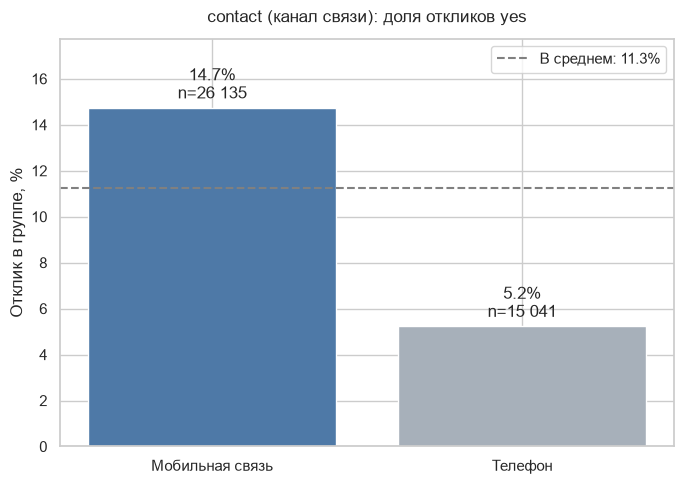

In [21]:
contact_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("contact", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(["cellular", "telephone"])
)

rates = contact_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Мобильная связь", "Телефон"],
    rates,
    color=["#4E79A7", "#A7B0BA"]
)

for bar, (_, row) in zip(bars, contact_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom"
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 3)
ax.set_title("contact (канал связи): доля откликов yes", pad=12)
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

### 5.5. month (месяц последнего контакта)

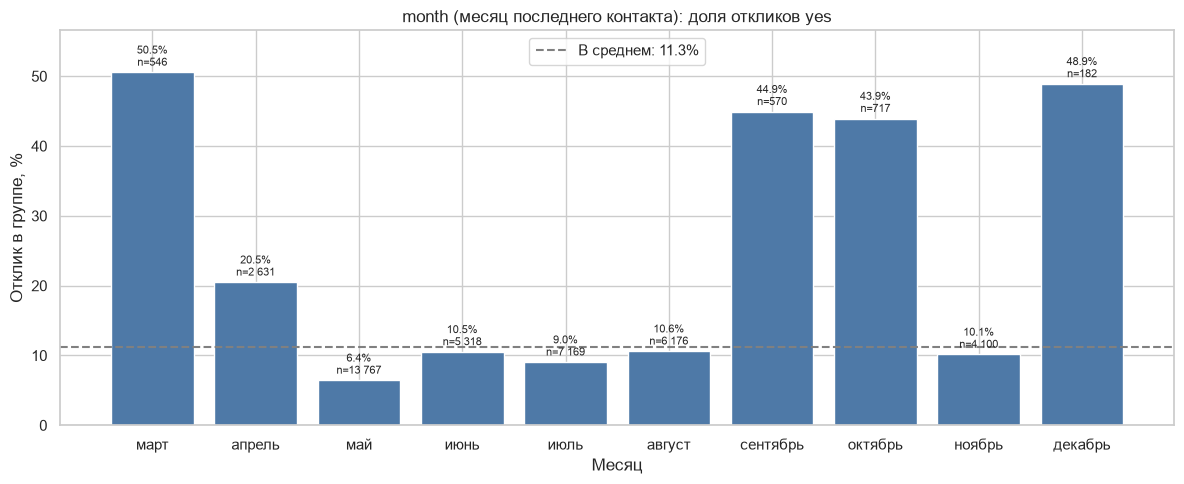

In [22]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

month_labels = {
    "mar": "март", "apr": "апрель", "may": "май", "jun": "июнь",
    "jul": "июль", "aug": "август", "sep": "сентябрь",
    "oct": "октябрь", "nov": "ноябрь", "dec": "декабрь"
}

month_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("month", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(month_order)
)

rates = month_summary["response_rate"] * 100
bars = None

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(
    [month_labels[m] for m in month_order],
    rates,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, month_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 6)
ax.set_title("month (месяц последнего контакта): доля откликов yes")
ax.set_xlabel("Месяц")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля отклика по месяцам заметно различается. В марте она составила 50,5%, в сентябре — 44,9%, но в этих группах было меньше контактов, чем, например, в мае. В мае контактов больше всего — 13 767, а отклик составил 6,4%. Поэтому высокий процент сам по себе не означает, что в этом месяце оформили больше всего вкладов.

### 5.6. day_of_week (день недели последнего контакта)

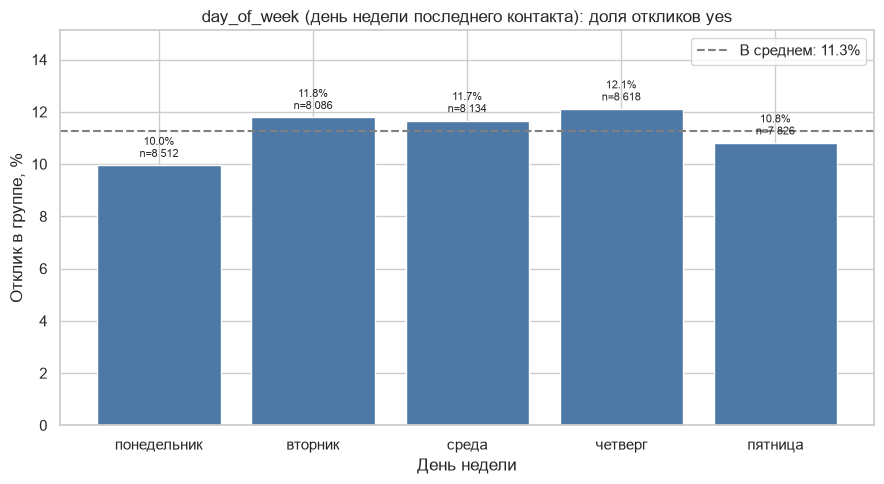

In [23]:
day_order = ["mon", "tue", "wed", "thu", "fri"]
day_labels = ["понедельник", "вторник", "среда", "четверг", "пятница"]

day_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("day_of_week", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(day_order)
)

rates = day_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(day_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, day_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.2,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 3)
ax.set_title("day_of_week (день недели последнего контакта): доля откликов yes")
ax.set_xlabel("День недели")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля отклика по дням недели близка к средней (11,3%) и меняется от 10,0% в понедельник до 12,1% в четверг. По этому графику заметных различий между днями недели не видно.

# 6. История контактов в предыдущих кампаниях

### 6.1 poutcome (результат предыдущей кампании)

poutcome содержит значение результата предыдущей кампании. Сравним долю текущих ответов y = yes для групп nonexistent, failure и success. В описании датасета не уточняется, по какому критерию результат отмечен как success.

poutcome описывает результат предыдущей кампании. Для прогноза до начала текущей кампании это исторический признак, поэтому сам по себе он не является утечкой — при условии, что это значение известно на момент прогноза. Категорию success трактуем только как отметку в исходном поле: точный критерий успеха в документации не указан.

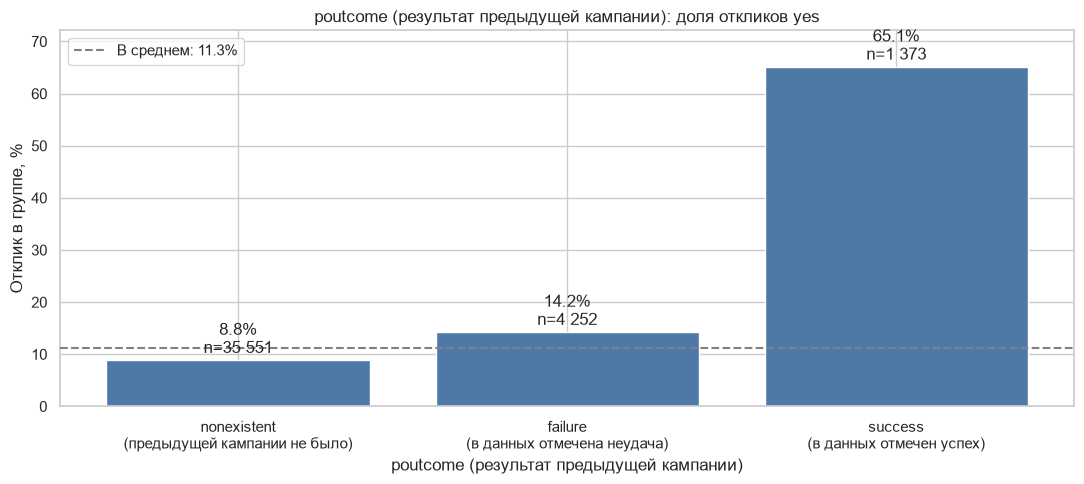

In [24]:
poutcome_order = ["nonexistent", "failure", "success"]

poutcome_labels = [
    "nonexistent\n(предыдущей кампании не было)",
    "failure\n(в данных отмечена неудача)",
    "success\n(в данных отмечен успех)"
]

poutcome_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("poutcome", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(poutcome_order)
)

rates = poutcome_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    poutcome_labels,
    rates,
    color=COLOR_MAIN
)

for bar, (_, row) in zip(bars, poutcome_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\n"
        f"n={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        zorder=4
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100

ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%",
    zorder=3
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("poutcome (результат предыдущей кампании): доля откликов yes")
ax.set_xlabel("poutcome (результат предыдущей кампании)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

В группе, где poutcome отмечено как success, доля текущих ответов yes составила 65,1%. После неудачного результата она составила 14,2%, а если предыдущей кампании не было — 8,8%. Успешный результат был только у 1 373 клиентов, поэтому он касается меньшей группы.

### 6.2. previous (контакты до текущей кампании)

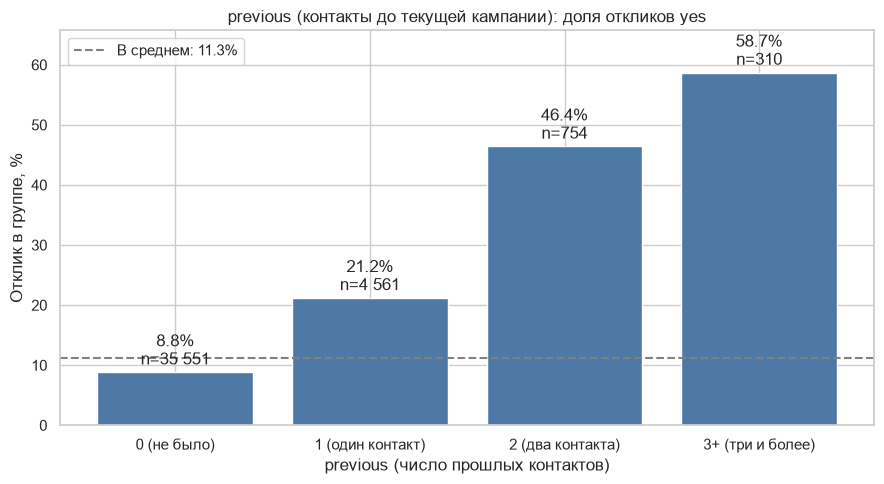

In [25]:
previous_order = ["0", "1", "2", "3+"]
previous_labels = [
    "0 (не было)",
    "1 (один контакт)",
    "2 (два контакта)",
    "3+ (три и более)"
]

previous_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        previous_group=df_clean["previous"].map(
            lambda value: "3+" if value >= 3 else str(value)
        )
    )
    .groupby("previous_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(previous_order)
)

rates = previous_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(previous_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, previous_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom"
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("previous (контакты до текущей кампании): доля откликов yes")
ax.set_xlabel("previous (число прошлых контактов)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля текущих ответов yes выше в группах с большим числом прошлых контактов: от 8,8% при previous = 0 до 58,7% при previous = 3+. При этом группы 2 и 3+ небольшие — 754 и 310 контактов, поэтому их высокий отклик нужно оценивать с осторожностью. По графику видно совпадение, но нельзя сказать, что именно прошлые контакты стали причиной отклика.

### 6.3. pdays (давность прошлого контакта)

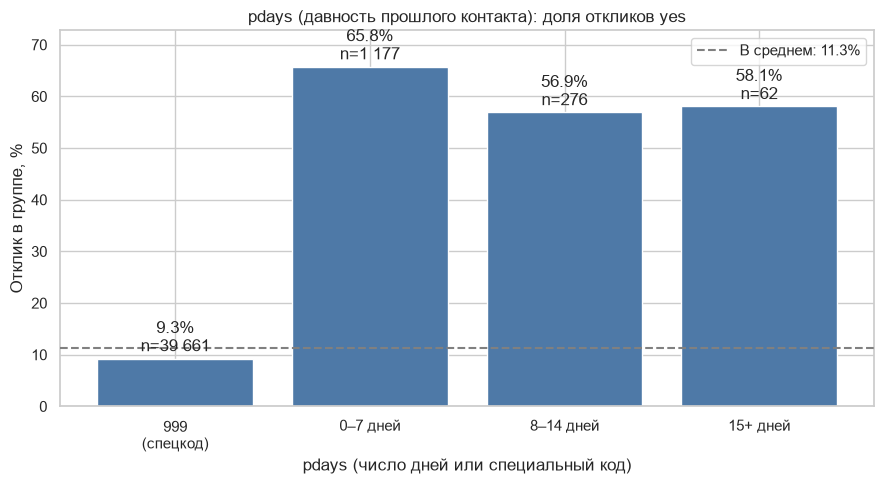

In [26]:
def group_pdays(value):
    if value == 999:
        return "999"
    elif value <= 7:
        return "0–7"
    elif value <= 14:
        return "8–14"
    else:
        return "15+"

pdays_order = ["999", "0–7", "8–14", "15+"]
pdays_labels = [
    "999\n(спецкод)",
    "0–7 дней",
    "8–14 дней",
    "15+ дней"
]

pdays_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        pdays_group=df_clean["pdays"].map(group_pdays)
    )
    .groupby("pdays_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(pdays_order)
)

rates = pdays_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(pdays_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, pdays_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        zorder=4
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%",
    zorder=3
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("pdays (давность прошлого контакта): доля откликов yes")
ax.set_xlabel("pdays (число дней или специальный код)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

При pdays = 999 доля текущих ответов yes составила 9,3% — ниже среднего по выборке (11,3%). В группах с числовым значением pdays она выше: от 56,9% до 65,8%. Но контактов в этих группах гораздо меньше, особенно в группе 15+ — всего 62, поэтому эти проценты стоит оценивать осторожно.

# 7. Число звонков в текущей кампании

### 7.1. campaign (число звонков клиенту)

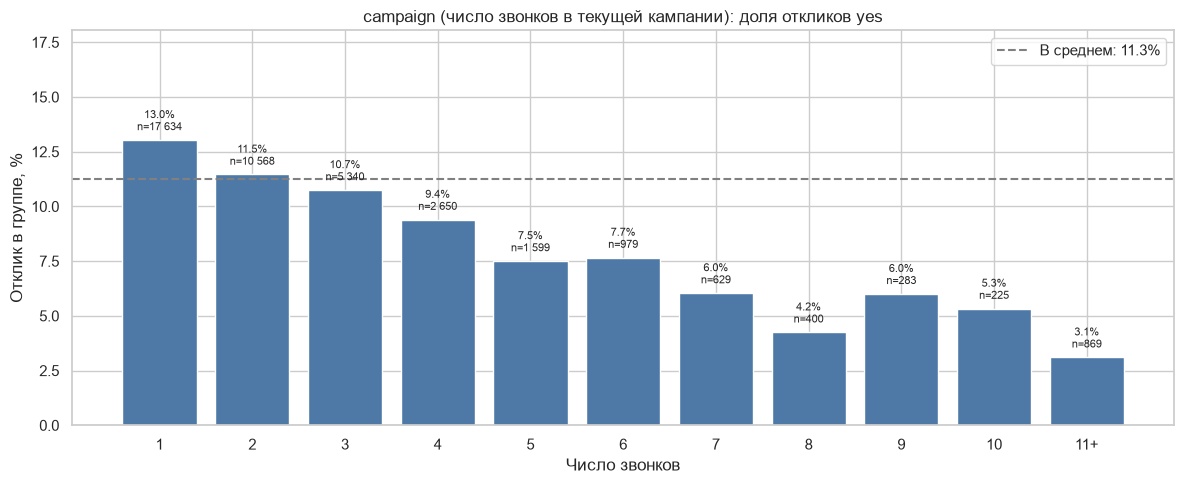

In [27]:
campaign_order = [str(n) for n in range(1, 11)] + ["11+"]

campaign_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        campaign_group=df_clean["campaign"].map(
            lambda value: str(value) if value <= 10 else "11+"
        )
    )
    .groupby("campaign_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(campaign_order)
)

rates = campaign_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(campaign_order, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, campaign_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 5)
ax.set_title("campaign (число звонков в текущей кампании): доля откликов yes")
ax.set_xlabel("Число звонков")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

На графике заметна общая тенденция: с ростом числа звонков доля yes снижается — с 13,0% при одном звонке до 3,1% при 11+. Снижение не строгое: например, для 9 звонков отклик немного выше, чем для 8. В этих группах меньше контактов, поэтому колебания процентов могут быть случайными.

# 8. Клиентский профиль

### 8.1. age (возраст клиента)

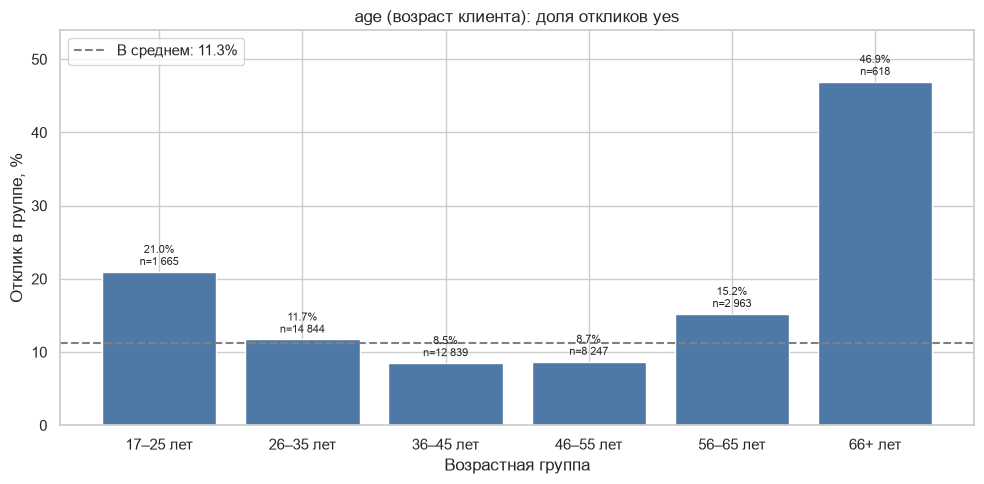

In [28]:
age_bins = [16, 25, 35, 45, 55, 65, 99]
age_labels = [
    "17–25 лет",
    "26–35 лет",
    "36–45 лет",
    "46–55 лет",
    "56–65 лет",
    "66+ лет"
]

age_summary = (
    df_clean.assign(
        is_yes=df_clean["y"].eq("yes").astype(int),
        age_group=pd.cut(
            df_clean["age"],
            bins=age_bins,
            labels=age_labels,
            include_lowest=True
        )
    )
    .groupby("age_group", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(age_labels)
)

rates = age_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(age_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, age_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("age (возраст клиента): доля откликов yes")
ax.set_xlabel("Возрастная группа")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля отклика выше у клиентов 17–25 лет (21,0%) и особенно у группы 66+ (46,9%). В группах 36–55 лет она ниже средней и составляет около 8,5–8,7%. В группе 66+ было 618 контактов — меньше, чем в большинстве остальных групп, поэтому высокий процент стоит оценивать с осторожностью. Доля отклика не растёт равномерно с возрастом.

### 8.2. marital (семейное положение)

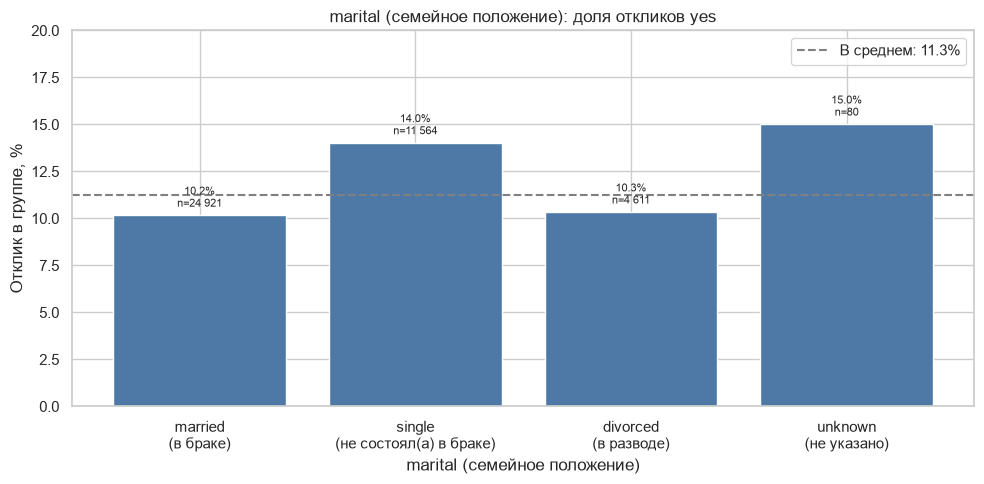

In [29]:
marital_order = ["married", "single", "divorced", "unknown"]

marital_labels = [
    "married\n(в браке)",
    "single\n(не состоял(а) в браке)",
    "divorced\n(в разводе)",
    "unknown\n(не указано)"
]

marital_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("marital", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(marital_order)
)

rates = marital_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(marital_labels, rates, color=COLOR_MAIN)

for bar, (_, row) in zip(bars, marital_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%"
)

ax.set_ylim(0, rates.max() + 5)
ax.set_title("marital (семейное положение): доля откликов yes")
ax.set_xlabel("marital (семейное положение)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

Доля отклика среди клиентов, не состоявших в браке, составила 14,0% — выше среднего (11,3%). Среди клиентов в браке и разведённых она близка: 10,2% и 10,3%. В категории unknown всего 80 контактов, поэтому её результат стоит оценивать осторожно.

### 8.3. default (есть ли просрочка по кредиту)

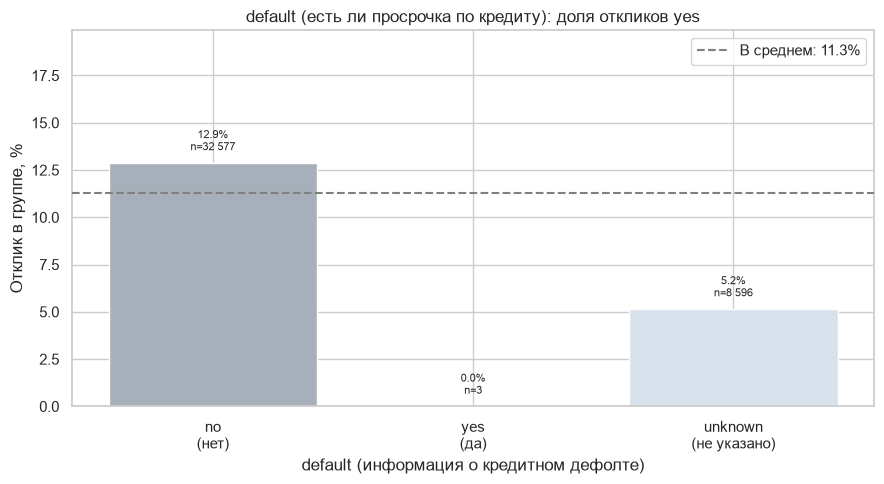

In [30]:
default_order = ["no", "yes", "unknown"]
default_labels = [
    "no\n(нет)",
    "yes\n(да)",
    "unknown\n(не указано)"
]

default_summary = (
    df_clean.assign(is_yes=df_clean["y"].eq("yes").astype(int))
    .groupby("default", observed=True)
    .agg(
        contacts=("y", "size"),
        response_rate=("is_yes", "mean")
    )
    .reindex(default_order)
)

rates = default_summary["response_rate"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    default_labels,
    rates,
    color=[COLOR_NO, COLOR_YES, "#D9E2EC"]
)

for bar, (_, row) in zip(bars, default_summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{row['response_rate'] * 100:.1f}%\nn={int(row['contacts']):,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontsize=8,
        zorder=4
    )

overall_rate = df_clean["y"].eq("yes").mean() * 100
ax.axhline(
    overall_rate,
    color="gray",
    linestyle="--",
    label=f"В среднем: {overall_rate:.1f}%",
    zorder=3
)

ax.set_ylim(0, rates.max() + 7)
ax.set_title("default (есть ли просрочка по кредиту): доля откликов yes")
ax.set_xlabel("default (информация о кредитном дефолте)")
ax.set_ylabel("Отклик в группе, %")
ax.legend()

plt.tight_layout()
plt.show()

В группе default = yes всего 3 контакта, и среди них нет ответов yes. Этой группы недостаточно, чтобы делать вывод о связи кредитного дефолта с откликом. В группе default = no отклик составил 12,9%, а при неизвестном значении — 5,2%.

# 9. duration (длительность разговора) и целевая переменная y

На boxplot в пункте 2.3 видно, что длительность разговора у клиентов с y = yes в целом выше, чем у клиентов с y = no. Однако duration становится известен только во время или после звонка. Поэтому этот признак можно анализировать в EDA, но нельзя использовать для прогноза до начала кампании: это приведёт к утечке данных.

Сильнее всего связаны макроэкономические признаки: emp.var.rate с euribor3m — 0,97, euribor3m с nr.employed — 0,95, emp.var.rate с nr.employed — 0,91. Это указывает на возможную мультиколлинеарность: часть признаков может содержать похожую информацию. Большинство остальных пар связаны слабо. При подготовке линейной модели проверим, нужны ли одновременно сильно коррелирующие макроэкономические признаки. Можно сравнить модель с отбором одного из них и модель с регуляризацией. Решение примем по качеству на проверочной выборке.

# 10. Итоги EDA
- В выборке 88,7% ответов no и 11,3% yes, поэтому классы распределены неравномерно.
- В группе contact = cellular доля отклика составила 14,7%, в группе telephone — 5,2%.
- Доля текущих ответов yes выше среди клиентов с poutcome = success — 65,1%. Она также растёт вместе с числом прошлых контактов, но в группах с 2 и более контактами наблюдений меньше.
- Отклик различается по месяцам, но в некоторых месяцах контактов мало. По дням недели заметных различий не видно.
- Между макроэкономическими признаками есть сильные корреляции. Например, корреляция emp.var.rate и euribor3m равна 0,97.

### Признаки для модели
Для прогноза до звонка можно рассматривать характеристики клиента и историю предыдущих контактов. contact, month и day_of_week подойдут, только если канал и время контакта известны до прогноза. default требует осторожности: в группе default = yes всего 3 записи.

duration и campaign оставляем в описательном анализе, но не используем для прогноза до начала кампании: эти значения становятся известны во время или после звонков. Для сильно коррелирующих макропризнаков при подготовке модели нужно решить, какие оставить.

## Сохранение обработанного датасета

In [33]:
parquet_path = "bank_marketing_clean.parquet"

df_clean.to_parquet(parquet_path, index=False)

print(f"Обработанный датасет сохранён: {parquet_path}")

Обработанный датасет сохранён: bank_marketing_clean.parquet


## Выводы по метрикам

### метрика выбрана по бизнес-задаче
- банк предсказывает вероятность подписки и решает, кому звонить
- в условии кейса **нет ограничения бюджета**
- **нет данных о стоимости звонка и прибыли депозита**, поэтому Expected Profit не считаем
- baseline - **Logistic Regression**

### какие метрики используем
| метрика | роль |
|---|---|
| **PR-AUC** | сравнение моделей (честная на дисбалансе, baseline = prevalence) |
| **Precision** | оценка качества на пороге (сколько оформили из тех, кому позвонили) |
| **Recall** | бизнес-цель (сколько реальных клиентов нашли) |

### что не используем
- **Accuracy** - обманывает при дисбалансе
- **ROC-AUC** - сглаживает разницу
- **F1** - симметрична, не учитывает бизнес-стоимость ошибок

## Baseline

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, 
    precision_score, 
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

df = pd.read_parquet('bank_marketing_clean.parquet')

X = df.drop(columns=['y', 'duration'])
y = (df['y'] == 'yes').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.25, 
    stratify=y, 
    random_state=42
)


num_features = X.select_dtypes(include=['int64', 'float64']).columns
cat_features = X.select_dtypes(include=['object']).columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

pipeline.fit(X_train, y_train)

y_pred_proba = pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_pred_proba >= 0.5).astype(int)



In [16]:
pr_auc = average_precision_score(y_test, y_pred_proba)
roc_auc = roc_auc_score(y_test, y_pred_proba)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
prevalence = y_test.mean()

print(f"PR-AUC: {pr_auc:.4f} - Наша модель в 4 раза лучше, чем случайное угадывание")
print(f"Precision: {precision:.4f} — Из всех, кому мы позвонили, реально купили {precision*100:.1f}%")
print(f"Recall:    {recall:.4f} — Мы нашли {recall*100:.1f}% от всех реальных клиентов, готовых купить депозит")

PR-AUC: 0.4288 - Наша модель в 4 раза лучше, чем случайное угадывание
Precision: 0.7114 — Из всех, кому мы позвонили, реально купили 71.1%
Recall:    0.1828 — Мы нашли 18.3% от всех реальных клиентов, готовых купить депозит


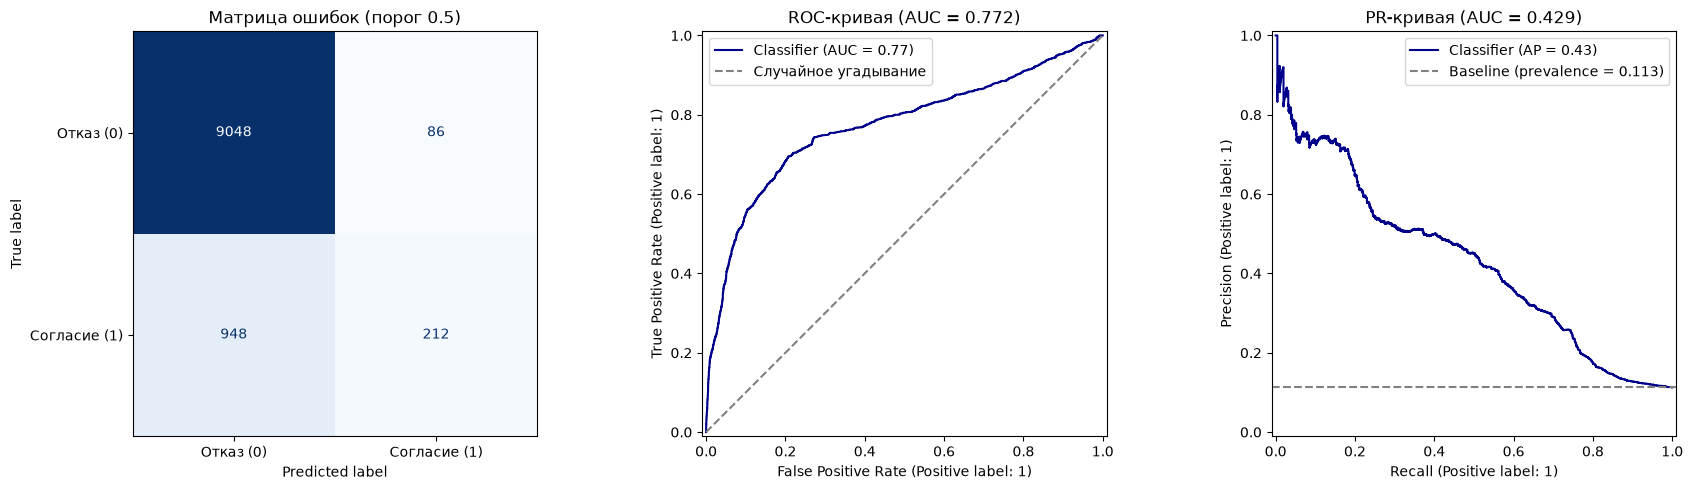

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# График 1: Матрица ошибок (Confusion Matrix)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Отказ (0)', 'Согласие (1)'],
    cmap='Blues',
    ax=axes[0],
    colorbar=False
)
axes[0].set_title('Матрица ошибок (порог 0.5)')

# График 2: ROC-кривая (справочно)
RocCurveDisplay.from_predictions(
    y_test, y_pred_proba,
    ax=axes[1],
    curve_kwargs={'color': 'darkblue'}
)
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Случайное угадывание')
axes[1].set_title(f'ROC-кривая (AUC = {roc_auc:.3f})')
axes[1].legend()

# График 3: Precision-Recall кривая (основная)
PrecisionRecallDisplay.from_predictions(
    y_test, y_pred_proba,
    ax=axes[2],
    curve_kwargs={'color': 'darkblue'}
)
axes[2].axhline(y=prevalence, color='gray', linestyle='--', label=f'Baseline (prevalence = {prevalence:.3f})')
axes[2].set_title(f'PR-кривая (AUC = {pr_auc:.3f})')
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

class BankFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_raw_pdays=False):
        self.drop_raw_pdays = drop_raw_pdays

    def fit(self, X, y=None):
        self.global_conf_mean_ = X['cons.conf.idx'].mean()
        self.job_conf_mean_ = X.groupby('job', observed=False)['cons.conf.idx'].mean()
        self.month_freq_ = X['month'].value_counts(normalize=True)
        return self

    def transform(self, X):
        X = X.copy()
        # 1. История контактов
        X['was_contacted'] = (X['pdays'] != 999).astype(int)
        X['pdays_clean'] = np.where(X['pdays'] == 999, -1, X['pdays'])
        X['has_previous_contacts'] = (X['previous'] > 0).astype(int)
        X['contact_intensity'] = X['campaign'] / (X['previous'] + 1.0)

        # 2. Макроэкономика
        X['age_euribor_interaction'] = X['age'] * X['euribor3m']
        X['real_rate_proxy'] = X['euribor3m'] - X['emp.var.rate']
        X['euribor_to_employed'] = X['euribor3m'] / (X['nr.employed'] / 1000.0)

        # 3. Агрегации (с защитой от новых категорий через fillna)
        X['job_cons_conf_mean'] = X['job'].map(self.job_conf_mean_).astype(float).fillna(self.global_conf_mean_)
        X['month_freq'] = X['month'].map(self.month_freq_).astype(float).fillna(0.0)

        if self.drop_raw_pdays and 'pdays' in X.columns:
            X = X.drop(columns=['pdays'])

        for col in categorical_features:
            X[col] = X[col].astype('category')

        return X